> **언어 전환 & 바로가기**: **🇰🇷 한국어 (현재 폴더: `notebooks/ko/`)** · [🇺🇸 English (`notebooks/en/stage1_asset_and_cq_en.ipynb`)](../en/stage1_asset_and_cq_en.ipynb) ｜ [스타터 README](../../README.md) ｜ [노트북 전체 인덱스 (README)](../README.md) ｜ [스타터 데모 열기](https://agentic-ontology-starter-115847445822.asia-northeast3.run.app/)
>
> **전체 라이프사이클 네비게이션**: [0. 전체 흐름 개요](./stage0_overview_walkthrough_ko.ipynb) → **[▶ Stage 1 · 준비·분석](./stage1_asset_and_cq_ko.ipynb)** → [Stage 2 · 파싱·통합](./stage2_wiki_and_semantic_graph_ko.ipynb) → [Stage 3 · 그래프 구축](./stage3_property_graph_bigquery_spanner_ko.ipynb) → [Stage 4 · 에이전트·답변](./stage4_agent_and_mcp_execution_ko.ipynb) → [Stage 5 · 리니지·검증](./stage5_lineage_and_evaluation_ko.ipynb)

---

# Stage 1. [준비 & 분석] Ready-to-Use 원천 자산 연결 · 테이블 스키마 설계 · 데이터 탐색 및 Golden CQ 정의
## Step 1.1 정형/비정형 자산 스코핑 및 스키마 블루프린트 · Step 1.2 데이터 탐색 및 Golden CQ 5종 / Boundary 10건 설계

Stage 1은 온톨로지 구축의 **Phase 1(준비)**과 **Phase 2(분석)**를 수행합니다. 에이전트가 답해야 할 핵심 역량 질문(**Golden CQ 5종**)과 경계 조건(**Boundary 10건**)을 먼저 확정하고, 이에 필요한 정형 CSV 6종과 비정형 가이드 2종이 적재된 Ready-to-Use BigQuery 10개 테이블(`starter_ontology_dw`)을 리소스 커넥터(`src/resource_connector.py` · `stage1_resource_check`)로 즉시 연결·검증합니다. 샘플 CSV는 비식별 합성 데모 데이터(`provenance=SYNTHETIC_DEMO`)입니다.

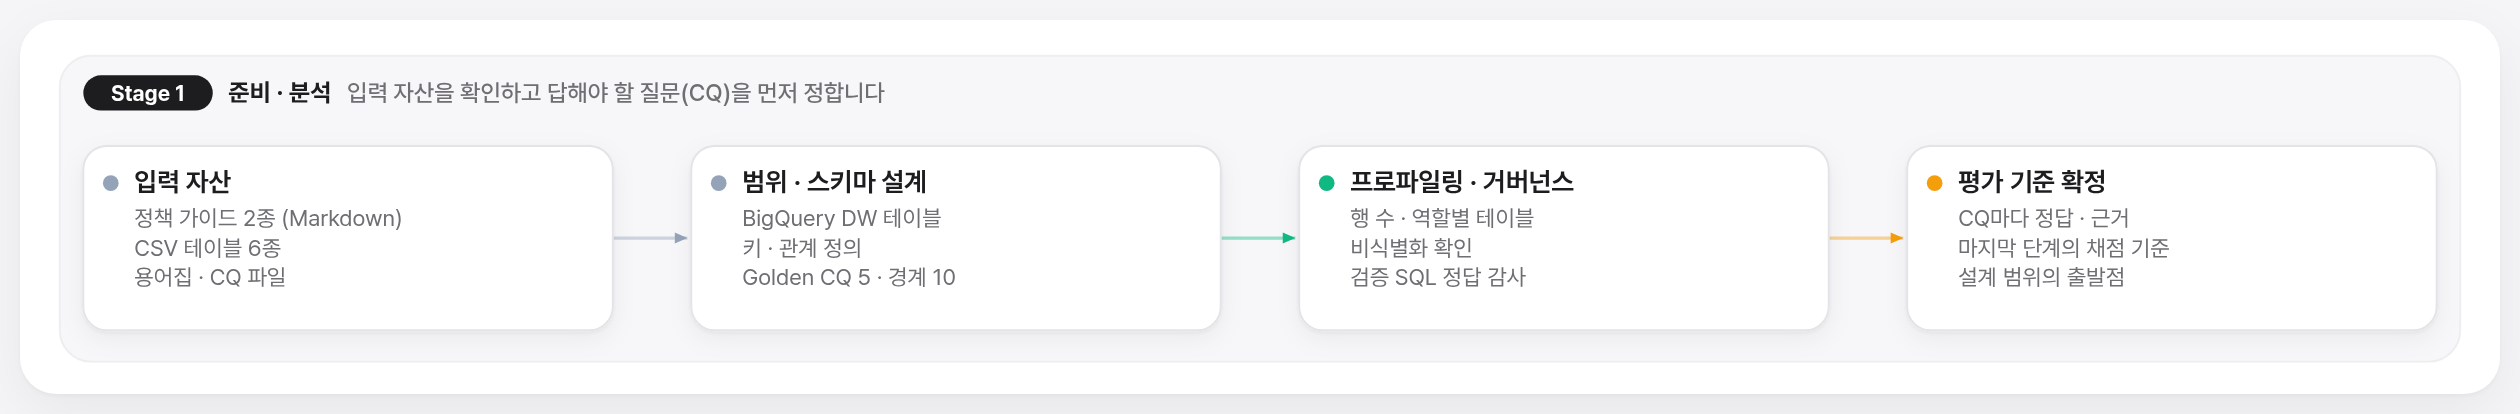


In [ ]:
%load_ext bigframes
import sys
from pathlib import Path
for _p in (Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent):
    if (_p / "nb_helpers.py").exists() and str(_p) not in sys.path:
        sys.path.insert(0, str(_p))
import pandas as pd
import nb_helpers as H
from src.agent.mcp_server import DomainMcpServer
H.setup("ko")
server = DomainMcpServer()


### 1. [Phase 1: 준비 (Preparation)] 원천 입력 자산(`data/input/`) 인벤토리 및 10개 테이블 스키마 설계도 (`%%bqsql`)


In [ ]:
H.show(H.raw_inputs_inventory())
H.draw_table_er_blueprint()


In [ ]:
%%bqsql df_schema
SELECT table_name,
       COUNT(*) AS column_count,
       STRING_AGG(CONCAT(column_name, ':', data_type), ', ' ORDER BY ordinal_position) AS columns_spec
FROM `seanjung-poc.starter_ontology_dw.INFORMATION_SCHEMA.COLUMNS`
GROUP BY table_name
ORDER BY table_name


In [ ]:
H.show(df_schema)


### 2. [Phase 2a: 분석 (Analysis)] Stage 1 리소스 검증(`stage1_resource_check`) 실행 — 테이블 프로파일링 및 비식별화 거버넌스 검증


In [ ]:
res_s1 = server.execute_tool("stage1_resource_check", {"steps": ["profile_tables", "scan_guides", "prune_noise", "tag_pii_governance"]})
H.show_tool(res_s1, "table_inventory")
H.show(pd.DataFrame([res_s1["pii_check"]]))


In [ ]:
%%bqsql df_tables
SELECT table_id, row_count, size_bytes,
  CASE WHEN STARTS_WITH(table_id, 'edge_') THEN 'edge'
       WHEN table_id IN ('tb_doc_chunks', 'tb_domain_rules') THEN 'knowledge'
       ELSE 'master' END AS kind
FROM `seanjung-poc.starter_ontology_dw.__TABLES__`
ORDER BY kind, table_id


In [ ]:
H.bar(df_tables, "table_id", "size_bytes", "starter_ontology_dw 테이블별 물리 크기 (Bytes)", horizontal=True)


### 3. [Phase 2b: 정형 원장 데이터 확인] 비식별 고객 약정(`CUST_DEMO_*`) · 단말 · 요금제 조인 및 180일 의무유지 경과일 분포 (`%%bqsql`)


In [ ]:
%%bqsql df_contracts
SELECT c.customer_id, c.contract_id, c.customer_segment, c.age_group, c.welfare_status, c.contract_type,
       c.elapsed_days, c.granted_subsidy_krw, d.device_name, p.plan_name, p.monthly_fee_krw
FROM `seanjung-poc.starter_ontology_dw.tb_customer_contract` c
JOIN `seanjung-poc.starter_ontology_dw.tb_device_master` d USING (device_id)
JOIN `seanjung-poc.starter_ontology_dw.tb_plan_master` p USING (plan_id)
ORDER BY c.customer_id


In [ ]:
H.show(df_contracts)
H.bar(df_contracts, "customer_id", "elapsed_days",
      "고객별 개통 경과일수 및 180일 의무유지 기준선",
      hline=180, hline_label="180d mandatory")


### 4. [Phase 2c: 지원금 정책 데이터 탐색] 단말기 × 요금제별 공시/추가지원금 구조 및 실구매가 히트맵 (`%%bqsql`)


In [ ]:
%%bqsql df_sub
SELECT s.policy_id, d.device_name, p.plan_name, p.monthly_fee_krw, d.factory_price_krw,
       s.base_subsidy_krw, s.additional_subsidy_cap_krw,
       s.base_subsidy_krw + s.additional_subsidy_cap_krw AS total_subsidy_krw,
       d.factory_price_krw - (s.base_subsidy_krw + s.additional_subsidy_cap_krw) AS net_price_krw,
       s.mandatory_retention_days
FROM `seanjung-poc.starter_ontology_dw.tb_subsidy_policy` s
JOIN `seanjung-poc.starter_ontology_dw.tb_device_master` d USING (device_id)
JOIN `seanjung-poc.starter_ontology_dw.tb_plan_master` p USING (plan_id)
ORDER BY d.device_name, p.monthly_fee_krw DESC


In [ ]:
d_sub = H.pdf(df_sub)
d_sub["device_plan"] = d_sub["device_name"].str.replace(" 256GB", "") + " / " + d_sub["plan_name"]
H.show(d_sub[["policy_id", "device_name", "plan_name", "monthly_fee_krw", "factory_price_krw", "base_subsidy_krw", "additional_subsidy_cap_krw", "total_subsidy_krw", "net_price_krw"]])
H.grouped_bar(d_sub, "device_plan", ["base_subsidy_krw", "additional_subsidy_cap_krw", "net_price_krw"],
              "단말 × 요금제별 공시지원금 · 추가지원금 · 실구매가 비교")
H.heatmap(d_sub.pivot(index="device_name", columns="plan_name", values="net_price_krw"),
          "단말 × 요금제 실구매가 히트맵 (KRW)")


### 5. [Phase 2d: 비정형 문서 · 용어사전 · Golden CQ 설계] 정책 청크 용어 빈도(`%%bqsql`) 및 Golden CQ 5종 정답 SQL 대조 검증


In [ ]:
%%bqsql df_terms
SELECT t.term, c.chunk_id, ARRAY_LENGTH(REGEXP_EXTRACT_ALL(c.content, t.pat)) AS hits
FROM `seanjung-poc.starter_ontology_dw.tb_doc_chunks` c,
UNNEST([
  STRUCT("공시지원금 (Subsidy)" AS term, r'(?i)subsidy|공시지원금' AS pat),
  STRUCT("유통망 상한 (15% Cap)", r'(?i)15%|additional|유통망'),
  STRUCT("180일 의무유지 (180d)", r'(?i)180-day|180 days|180일'),
  STRUCT("일할 차액정산 (Prorated)", r'(?i)formula|prorated|일할|차액정산'),
  STRUCT("위약금 (Penalty)", r'(?i)penalty|위약금'),
  STRUCT("선택약정 25% (Selective)", r'(?i)selective|25%|선택약정'),
  STRUCT("복지 면제 (Welfare)", r'(?i)welfare|exempt|복지|면제')
]) AS t
ORDER BY t.term, c.chunk_id


In [ ]:
glossary = H.read_json("data/input/05_glossary/business_glossary.json")
H.show(pd.DataFrame([{"term": k, "definition": v} for k, v in glossary.items()] if isinstance(glossary, dict) else glossary))
df_terms_loc = H.pdf(df_terms)
H.heatmap(df_terms_loc.pivot(index="term", columns="chunk_id", values="hits"),
          "핵심 도메인 용어 × 정책 문서 청크 출현 빈도", fmt="{:.0f}")
cqs = H.read_json("data/input/04_cq/golden_competency_questions.json")
H.show(H.check_cq_sql(cqs))
bcs = H.read_json("data/input/04_cq/boundary_cases.json")
H.show(bcs, ["case_id", "root_cause_code", "missing_context", "query", "expected_behavior"])


### 6. [Phase 2e: 그래프 엔진 선택 5축 의사결정 체크리스트] BigQuery Property Graph(기본값) · Cloud Spanner Graph(100 PU) · Graph Fabric(`both`) 선정 기준 확인


In [ ]:
H.show(H.engine_selection_checklist_df())


### Q&A
- **Q.** 왜 온톨로지와 그래프를 만들기 전에 Golden CQ와 `verification_sql`, 그리고 5축 그래프 엔진 선택 체크리스트를 먼저 정의하나요?
  - **A.** 에이전트가 답해야 할 질문과 결정론적 정답 산식(`expected_math`, `verification_sql`, `grounded_chunk`), 그리고 워크로드 특성(원천 저장소, 지연시간 SLO, 동시 처리량, 갱신 주기, 데이터 규모)에 따른 물리 그래프 엔진(`bigquery` 기본값 | `spanner` | `both`)을 Stage 1에서 먼저 확정해야 불필요한 테이블 적재나 인프라 과투자를 막고 Stage 3·5에서 정량 검증할 수 있기 때문입니다.

### Data Analysis Key Findings
- `starter_ontology_dw` 내 10개 테이블 스키마(`INFORMATION_SCHEMA.COLUMNS`)와 62개 행이 정상 적재되었으며, `CUST_DEMO_001~006` 비식별 규칙 위반 건수는 `0건`입니다.
- 6명의 고객 약정 중 5건(`elapsed_days`: 45~120일)이 180일 의무유지 기간 이내에 있어 요금제 하향 시 일할 차액정산 또는 복지 면제 규칙 판정이 필요합니다.
- Golden CQ 5종(`CQ-01`~`CQ-05`)의 `verification_sql`을 BigQuery에서 직접 실행한 결과, `expected_math`와 5건 모두 일치(`match=True`)하며, 5축 그래프 엔진 체크리스트(`input_manifest.json`)를 통해 기본값인 `bigquery`와 듀얼 엔진(`both`) 구성 기준을 확인했습니다.

### Insights or Next Steps
- 다음 단계인 `Stage 2 (파싱·통합)` 노트북으로 이동하여 비정형 정책 가이드 마크다운을 SHA-256 해시 앵커 청크로 파싱하고, Karpathy 3-Layer LLM-Wiki 및 시맨틱 온톨로지 그래프로 통합하는 과정을 확인하세요.

---
> **다음 학습 이동 (Navigation)**: [⬅️ 0. 전체 흐름 개요](./stage0_overview_walkthrough_ko.ipynb) ｜ [🏠 0. 전체 흐름 초기 화면](./stage0_overview_walkthrough_ko.ipynb) ｜ [➡️ Stage 2 · 파싱·통합](./stage2_wiki_and_semantic_graph_ko.ipynb) ｜ [🌐 English Version](../en/stage1_asset_and_cq_en.ipynb) ｜ [📖 방법론 문서](../../methodology/ko/01_stage1_asset_and_cq_ko.md)
